# 033 — GM record selection, AvgSA([0, 3]) — Stage 2 (post-processing)

Loads the complete `AvgSA_03_final_ensembles.pickle` (merged/maintained by nb `032`) and writes the
per-`(site, iml)` **stripe pickles + `.manifest.json` sidecars**. Those manifests are the canonical,
incremental record of "what has been selected and is still valid": a stripe whose manifest already
matches its per-stripe fingerprint is left untouched, so only the missing/stale stripes are
(re)written. Runs in seconds; it never triggers the hour-long selection.

**Excluded records** — the stale check is versioned by the exclusion list
(`UNAVAILABLE_RECORDS`, via `stripe_fingerprints`), exactly as in nb 032: a stripe selected under
an older version of the list stays valid (and is not rewritten) as long as it contains none of the
records excluded since. A stale stripe for which nb 032 found no complete record set stops the
notebook if its old pickle is still on disk, so its old records cannot reach the download lists.

**Upstream**:
- `AvgSA_03_final_ensembles.pickle` (+ manifest) — the complete selection from nb `032`.
- `gcim_dist_AvgSA_03.pickle` (nb `031`) — for the per-ensemble `gcim_quantiles`.
- `setup_AvgSA03_gcim_gm_selection(sites=())` — for the selection context (per-stripe fingerprint).
  Called with `sites=()`, so **no disagg shard is opened**: this notebook needs only the context, the
  disagg *stats* (for the `poe` metadata) and `wanted_stripe_keys()` (orphan pruning + cross-site
  aggregation), all of which are cheap.

**Output**:
- Per-`(site, iml)` ensemble pickles `site_{id}__stripe_iml_{iml}__gm_selection.pickle` (+ a
  `.manifest.json` each) in `config.ss_dir(cfg, "results", "record_selection", "AvgSA_03__ks")` — enriched with `poe`/`rtp`,
  `gcim_quantiles`, `trt_stats`, and per-record `RSN`/`record_identifier`/`filename`. The iml token is
  zero-padded / `pt`-encoded (e.g. `01pt150`); `standes` orders stripes by parsing it back to a float.
- Record-download summaries `AvgSA_03_summary_esm_records_selected.csv`,
  `AvgSA_03_summary_ngasub_records_selected.csv`, and `AvgSA_03_records_to_convert.csv` — built from
  **all** stripes on disk (not just the incremental batch).

**Run order** — run top to bottom after `032`. Runs in seconds (source-file hashes are streamed and
memoised per process, so the same inputs are read once rather than once per stripe); safe to re-run.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

from phd_project.config import config
from phd_project.config.config import load_config
from phd_project.scripts.cache_utils import fingerprint, verify, write_manifest
from phd_project.scripts.disagg_shards import shards_digest
from phd_project.scripts.WP1_ground_motion_set.gm_selection import (
    get_poe_from_disaggstats, iml_filename_tag,
    stripe_pickle_path, find_stale_stripes, ensemble_accepted)
from phd_project.scripts.WP1_ground_motion_set.setup_AvgSA03_gm_selection import (
    setup_AvgSA03_gcim_gm_selection, wanted_stripe_keys, SELECTION_CONFIG,
    stripe_source_fps, stripe_fingerprints)

cfg = load_config()
# SIDE QUEST (see side-quest_gm_selection_optimisation/README.md). This notebook belongs to
# ONE record set, pinned here - not the active study - so re-running it only ever touches
# that set's folders. GRID is the set's frozen stripe grid (a copy of the stripe IMLs as
# they were when the side quest ran), so stripes added to the main line later are ignored.
SS = "AvgSA_03__ks"
GRID = config.stripe_grid_path(cfg, SS)

# paths
gcim_dist_fp = cfg["proc_data"]["gcim_dists"] / "gcim_dist_AvgSA_03.pickle"
final_ensembles_fp = config.ss_dir(cfg, "proc_data", "gm_selection", SS) / "AvgSA_03_final_ensembles.pickle"
esm_records_selected_fp = config.ss_dir(cfg, "proc_data", "gm_selection", SS) / "AvgSA_03_summary_esm_records_selected.csv"
ngasub_records_selected_fp = config.ss_dir(cfg, "proc_data", "gm_selection", SS) / "AvgSA_03_summary_ngasub_records_selected.csv"
records_to_convert_fp = config.ss_dir(cfg, "proc_data", "gm_selection", SS) / "AvgSA_03_records_to_convert.csv"
disagg_stats_fp = cfg["proc_data"]["AvgSA_03_disagg_stats_gm_selection"]
disagg_shard_dir = cfg["proc_data"]["AvgSA_03_disagg_data_shards"]
RESULT_FOLDER = config.ss_dir(cfg, "results", "record_selection", SS)

# The selection context (for the per-stripe fingerprint) comes from setup, with
# sites=() so NO disagg shard is opened — this notebook never needs the disagg data
# itself, only the context, the stats (for the poe metadata) and the wanted key set
# (for orphan pruning + cross-site aggregation), all of which are cheap.
_, disagg_stats, site_model, basic_selection_ctx, _ = setup_AvgSA03_gcim_gm_selection(sites=(), imls_for_selection_fp=GRID)
wanted = wanted_stripe_keys(imls_for_selection_fp=GRID)
source_fps_stripe = stripe_source_fps()
# Versioned by exclusion list -- the same stale check as nb 032 (see
# setup_AvgSA03_gm_selection.stripe_fingerprints). fp_fn is the CURRENT fingerprint, the
# one every manifest written below records.
fp_fn, superseded = stripe_fingerprints(
    SELECTION_CONFIG, source_fps_stripe, basic_selection_ctx, disagg_stats)

# load the batch that nb 032 just (re)selected, plus its gcim (both per-batch scratch)
with open(final_ensembles_fp, "rb") as f:
    final_ensembles = pickle.load(f)
with open(gcim_dist_fp, "rb") as f:
    gcim_dists = pickle.load(f)

# The batch-artifact provenance check (verify on final_ensembles) is in the next code
# cell: it only runs when there is something to write from final_ensembles.

# Provenance stamp for the download/convert CSVs written below.
csv_provenance = fingerprint(final_ensembles=final_ensembles_fp)

C:\Users\clemettn\Documents\phd\phd_project\scripts\WP1_ground_motion_set\gm_selection.py:15: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


Built 0 (site, iml) disaggregations across 0 sites (0 of 60 shards loaded; 532 (site, iml) wanted in total).


## Save (re)selected per-(site, iml) stripes + surface record identifiers

Writes only the stale/new stripes -- every one with a complete 30-record set, **whether or not it passes KS** (KS failures are still listed on screen) -- (each with a `.manifest.json` that makes it a valid cache entry),
prunes any stripe whose `(site, iml)` is no longer in the union lists, then aggregates record
identifiers across **all** stripes on disk.

In [3]:
# Save the (re)selected stripes into the results folder. Each stripe pickle carries a
# .manifest.json (its per-stripe fingerprint) which IS the incremental cache: a stripe
# whose manifest already matches is left untouched. final_ensembles is the COMPLETE set,
# so we only (re)write the stale/new stripes; writing the manifest marks a stripe "valid".
DISAGG_IMT = "AvgSA"  # conditioning IM name used to look up the poe metadata

to_compute, valid = find_stale_stripes(wanted, RESULT_FOLDER, fp_fn, superseded=superseded)
print(f"{len(valid)} stripe(s) already valid on disk; (re)writing {len(to_compute)}.")

# Refuse to post-process a stale batch artifact: confirm the source files that produced
# final_ensembles are unchanged (hashes only -- nothing heavy is loaded). final_ensembles
# spans every site in its batch, so its disagg input is the whole-shard-set digest.
# db_exclusions is also checked, so a final-ensembles file built WITHOUT the database
# filter (or with a different exclusion list) is refused.
#
# Checked only when there is something to write. nb 032 rewrites the final-ensembles
# manifest whenever it selects a batch, so the manifest describes the LAST batch selected.
# On a run with nothing to (re)write it may legitimately predate the current inputs (e.g.
# the exclusion list grew without making any stripe of this selection stale), and
# checking it would refuse a run that consumes nothing from it.
if to_compute:
    verify(final_ensembles_fp, fingerprint(
        gm_db_file=cfg["proc_data"]["gm_database"],
        gcim_file=gcim_dist_fp,
        disagg_shards_digest=shards_digest(disagg_shard_dir),
        disagg_stats_file=disagg_stats_fp,
        site_model_file=cfg["hazard_models"]["eshm20_wp1_site_model"],
        db_exclusions=repr(SELECTION_CONFIG["db_exclusions"]),
    ))
    print("Batch artifact provenance verified (including the database exclusion).")

# Stale stripes for which there is no complete record set to write, but whose OLD
# pickle is still on disk (checked after the loop).
stale_kept = []

# WRITE GATE -- every stripe with a COMPLETE record set is written, whether or not it
# passes KS. "Complete" = ensemble_accepted(..., "complete_set"): the set exists, has
# n_samples (30) records and no empty row -- the same test the __mu_sigma selection
# uses as its acceptance. This is deliberately looser than the KS acceptance nb 032
# selects against: nb 032 still tries to make every stripe pass KS, but a stripe it
# could not fix is now KEPT (written) rather than dropped. KS stays in the stripe as a
# diagnostic (ks_passed / ks_results / ks_failed_ims), and every stripe that fails KS
# is still listed on screen ("No valid ensemble: ..."), exactly as before.
#
# NOTE: writing a stripe also writes its manifest, which makes it "valid" for
# find_stale_stripes. nb 032 will therefore NOT reselect a written KS-failing stripe on
# its next run unless its fingerprint changes (new exclusions, new inputs, ...).
n_samples = basic_selection_ctx["n_samples"]
n_written_failing_ks = 0   # written this run although failing KS
n_not_written = 0          # no complete set: nothing to write

for (site, iml) in to_compute:
    ensemble = final_ensembles.get((site, iml))
    has_full_set = ensemble_accepted(ensemble, "complete_set", n_samples)
    passes_ks = ensemble_accepted(ensemble, "ks")

    # The failure list, printed as before: every stripe without a KS-passing complete
    # set -- both those written anyway and those with nothing to write.
    if not (has_full_set and passes_ks):
        print(f"No valid ensemble: Site {site} - iml = {iml}")

    if not has_full_set:
        n_not_written += 1
        # The old pickle stays stale (it is never trusted as valid), but the summary and
        # download cells below are built from EVERY stripe pickle on disk, so they would
        # quietly carry its old records -- e.g. one that has since been excluded -- into
        # the download / convert lists.
        if stripe_pickle_path(RESULT_FOLDER, site, iml).is_file():
            stale_kept.append((site, iml))
        continue

    n_written_failing_ks += not passes_ks

    # Stripe identifiers required by standes.analysis.msa.read_stripe_selection.
    # poe is 1:1 with iml per site; derive it from the disagg stats (metadata only).
    poe = get_poe_from_disaggstats(disagg_stats, site, DISAGG_IMT, iml)
    ensemble["poe"] = float(poe)
    # annual PoE -> return period via the Poisson/exponential model:
    # poe = 1 - exp(-1/rtp)  =>  rtp = -1 / ln(1 - poe)
    ensemble["rtp"] = round(-1.0 / np.log(1.0 - poe))

    # Add the gcim_quantiles from the result
    ensemble["gcim_quantiles"] = gcim_dists[(site, iml)]["stats"]

    # calculate the trt %'s
    trt_stats = pd.DataFrame(
        ensemble["recs"].groupby(("metadata", "trt")).size())
    trt_stats.columns = ["count"]
    trt_stats["proportions"] = np.round(trt_stats["count"] / \
                                        trt_stats["count"].sum(), 3)
    ensemble["trt_stats"] = trt_stats

    # Surface RSN + a stable record identifier and JSON filename per record.
    recs = ensemble["recs"]
    is_ngasub = recs[("metadata", "database")] == "NGASub"

    # RSN: already present as metadata.index for NGASub; NA for ESM.
    recs[("metadata", "RSN")] = (
        recs[("metadata", "index")].astype("string").where(is_ngasub)
    )

    # record_identifier: ESM uses event/station/location; NGASub uses the RSN.
    esm_id = (
        recs[("metadata", "event_id")].astype(str) + "_"
        + recs[("metadata", "station_code")].astype(str) + "_"
        + recs[("metadata", "location_code")].astype(str)
    )
    recs[("metadata", "record_identifier")] = esm_id.where(
        ~is_ngasub, recs[("metadata", "index")].astype(str)
    )

    # filename: {record_identifier}__{component}.json
    recs[("metadata", "filename")] = (
        recs[("metadata", "record_identifier")].astype(str)
        + "__" + recs[("metadata", "component")].astype(str) + ".json"
    )

    stripe_fp = stripe_pickle_path(RESULT_FOLDER, site, iml)
    with open(stripe_fp, "wb") as file:
        pickle.dump(ensemble, file)
    # The manifest is what makes this stripe "valid" on the next run.
    write_manifest(stripe_fp, fp_fn(site, iml))

# One-line tally of the gate above, so the failure list can be read at a glance.
print(f"Wrote {len(to_compute) - n_not_written} stripe(s) this run, {n_written_failing_ks} "
      f"of them failing KS (written anyway: complete {n_samples}-record set); "
      f"{n_not_written} stripe(s) without a complete set not written.")

# Prune orphans: stripe files whose (site, iml) is no longer wanted (e.g. an IML was
# removed from the union lists). This replaces the old blanket delete-all, which would
# have wiped the incremental cache.
wanted_names = {stripe_pickle_path(RESULT_FOLDER, s, i).name for (s, i) in wanted}
for old in RESULT_FOLDER.glob("*__stripe_*__gm_selection.pickle"):
    if old.name not in wanted_names:
        old.unlink()
        old.with_name(old.name + ".manifest.json").unlink(missing_ok=True)
        print(f"Pruned orphan stripe: {old.name}")

# Stop before the cells below fold old, stale record sets into the summaries and the
# download / convert lists (see stale_kept above).
if stale_kept:
    raise RuntimeError(
        f"{len(stale_kept)} stale stripe(s) have no complete record set to replace them, but "
        f"their OLD pickle is still in {RESULT_FOLDER} and would be folded into the "
        f"download / convert lists below: {stale_kept}. Check why the selection failed "
        f"(nb 032, 'still failing' cell). If the stripe is to have no record set, "
        f"delete its pickle and .manifest.json from that folder, then re-run this notebook.")

532 stripe(s) already valid on disk; (re)writing 0.


## Identify the number of unique records and unique events across all sites

In [4]:
# combine ALL stripes on disk into one dataframe (the whole record set, not just the
# incremental batch) so the summaries / download CSVs below cover every selected stripe.
rec_dfs = []
for p in sorted(RESULT_FOLDER.glob("*__stripe_iml_*__gm_selection.pickle")):
    with open(p, "rb") as f:
        rec_dfs.append(pickle.load(f)["recs"])

all_recs = pd.concat(rec_dfs, axis=0)
events = all_recs.groupby(("metadata", "event_id")).size().sort_values(ascending=False)
events = pd.DataFrame(events, columns=["count"])
events["cum_sum"] = events["count"].cumsum() 
events["cum_%"] = np.round(events["cum_sum"] / events["count"].sum() * 100, 4)

recs_and_events = all_recs.reset_index().groupby([("metadata", "event_id"), "index"])\
    .size().sort_values(ascending=False)
recs_and_events = pd.DataFrame(recs_and_events, columns=["count"])
recs_and_events["cum_sum"] = recs_and_events["count"].cumsum() 
recs_and_events["cum_%"] = np.round(recs_and_events["cum_sum"] / recs_and_events["count"].sum() * 100, 4) 
recs_and_events

print(f"Number of unique events: {len(events)}")
print(f"Number of unique records: {len(recs_and_events)}")
print(f"Maximum number of times a record was selected: {recs_and_events["count"].iloc[0]} ({recs_and_events["count"].iloc[0] / len(all_recs)*100:.2f} %)")

Number of unique events: 291
Number of unique records: 2343
Maximum number of times a record was selected: 309 (1.94 %)


In [5]:
recs_and_events

count  cum_sum     cum_%
(metadata, event_id) index                          
ME-1979-0003         19497    309      309    1.9361
ME-1979-0012         39843    305      614    3.8471
IT-1997-0137         12649    266      880    5.5138
IT-1976-0027         32609    261     1141    7.1491
GR-1999-0001         12019    244     1385    8.6779
...                           ...      ...       ...
1000081              86077      1    15956   99.9749
                     41985      1    15957   99.9812
1000071              41667      1    15958   99.9875
1000006              86415      1    15959   99.9937
                     84860      1    15960  100.0000

[2343 rows x 3 columns]

(0.0, 304.5)

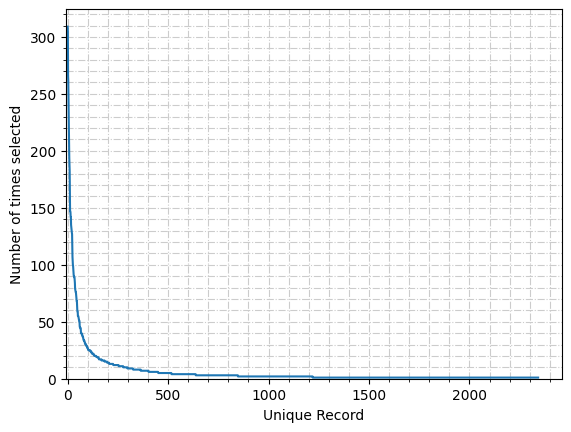

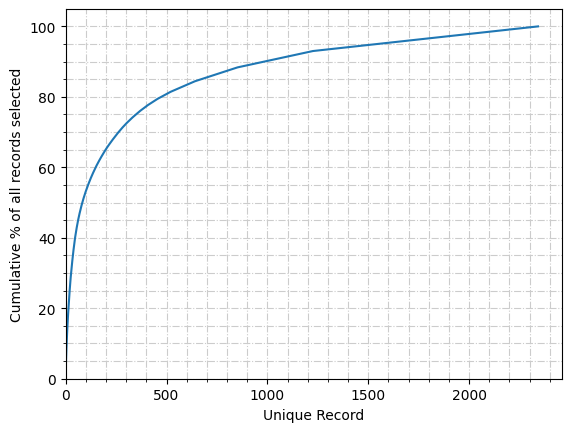

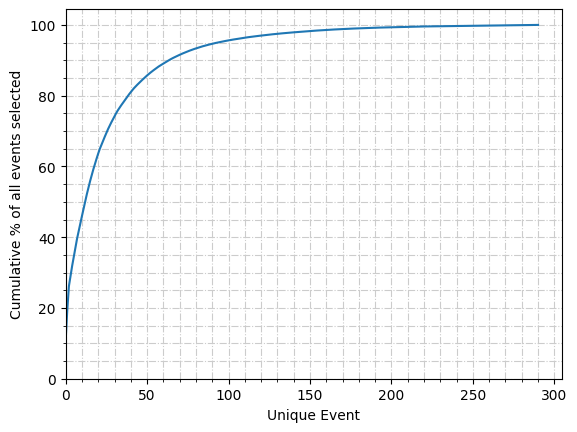

In [6]:
fig, ax3 = plt.subplots()
ax3.plot(recs_and_events["count"].to_numpy())
ax3.grid(True, which="both", ls="-.", color="0.8")
ax3.minorticks_on()
ax3.set_xlabel("Unique Record")
ax3.set_ylabel("Number of times selected")
ax3.set_ylim(0)
ax3.set_xlim(-10)

fig, ax1 = plt.subplots()
ax1.plot(recs_and_events["cum_%"].to_numpy())
ax1.grid(True, which="both", ls="-.", color="0.8")
ax1.minorticks_on()
ax1.set_xlabel("Unique Record")
ax1.set_ylabel("Cumulative % of all records selected")
ax1.set_ylim(0)
ax1.set_xlim(0)

fig, ax2 = plt.subplots()
ax2.plot(events["cum_%"].to_numpy())
ax2.grid(True, which="both", ls="-.", color="0.8")
ax2.minorticks_on()
ax2.set_xlabel("Unique Event")
ax2.set_ylabel("Cumulative % of all events selected")
ax2.set_ylim(0)
ax2.set_xlim(0)


## Records to download / convert

In [7]:
cols_to_keep = [("metadata", "event_id"), ("metadata", "station_code"), ("metadata", "location_code")]
unique_esm_records = all_recs[all_recs[("metadata", "database")] == "ESM"]\
                     .drop_duplicates(subset=cols_to_keep)
unique_esm_records = unique_esm_records[cols_to_keep].reset_index(drop=True)
esm_records_selected = unique_esm_records
esm_records_selected.to_csv(esm_records_selected_fp, index=False)
write_manifest(esm_records_selected_fp, csv_provenance)

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_summary_esm_records_selected.csv.manifest.json')

In [8]:
# For the NGASub records we need the NGAsubRSN for each combination of event_id and station_code
NGASub_records = all_recs[all_recs[("metadata", "database")] == "NGASub"]
unique_NGASub_id_counts = NGASub_records.groupby(
    [("metadata", "event_id"), ("metadata", "station_code")]).size().sort_values(ascending=False)
unique_NGASub_id_counts = unique_NGASub_id_counts.rename("count")

# load the NGASub database
ngasub_fp = cfg["raw_data"]["gm_flatfiles"] / "NGASub_Metadata_SA_rotD50.csv"
ngasub_db = pd.read_csv(ngasub_fp, header=0, encoding="cp1252", dtype=str)
new_index = list(ngasub_db[["NGAsubEQID", "NGAsubSSN"]].itertuples(index=False, name=None))
ngasub_db.index = new_index
ngasub_db = ngasub_db["NGAsubRSN"]

# RSNs to download
rsns_selected = ngasub_db.loc[unique_NGASub_id_counts.index]
rsns_selected = pd.concat([rsns_selected, unique_NGASub_id_counts], axis=1)
rsns_selected.to_csv(ngasub_records_selected_fp, index=False)
write_manifest(ngasub_records_selected_fp, csv_provenance)

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_summary_ngasub_records_selected.csv.manifest.json')

In [9]:
# Per-campaign record-conversion list (record_identifier, component, database, network_code)
# for the AT2/HDF5 -> JSON converters. Combined across campaigns in
# wp1pt3pt8i-organise_records_to_download.
#
# network_code (added 2026-09-30): an ESM HDF5 file can hold the same station code for TWO
# networks (e.g. GE.KTHA and HL.KTHA), and the record identifier {event}_{station}_{location}
# cannot tell them apart. The network the selection actually chose is looked up from the
# selection database by each record's row label (the index of `recs`), which works for stripes
# selected before the column existed as well as after. The lookup also checks that event,
# station and component still agree with the database row.
import phd_project.scripts.WP1_ground_motion_set.manage_flatfiles as mf

all_meta = all_recs["metadata"].copy()
all_meta["network_code"] = mf.network_code_lookup(cfg["proc_data"]["gm_database"], all_recs)

records_to_convert = (
    all_meta[["record_identifier", "component", "database", "network_code"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# The JSON file name is {record_identifier}__{component}.json, with no network in it. That is
# only unambiguous while no (record_identifier, component) was selected from BOTH networks of a
# pair. It is not the case on 2026-09-30; stop loudly if a future selection makes it happen,
# because two different waveforms would then have to share one JSON.
n_nets = (records_to_convert[records_to_convert["database"] == "ESM"]
          .groupby(["record_identifier", "component"])["network_code"].nunique())
if (n_nets > 1).any():
    raise ValueError("These ESM records were selected from more than one network and would "
                     f"share a JSON file name:\n{n_nets[n_nets > 1]}")

records_to_convert.to_csv(records_to_convert_fp, index=False)
# The list now also depends on the database (for network_code), so its hash is recorded too.
# nb 040 verifies only the final_ensembles entry; the extra key does not affect that check.
write_manifest(records_to_convert_fp, fingerprint(
    final_ensembles=final_ensembles_fp, gm_db_file=cfg["proc_data"]["gm_database"]))

WindowsPath('C:/Users/clemettn/Documents/phd/data_processed/06_gm_selection/AvgSA_03_records_to_convert.csv.manifest.json')